In [1]:
import csv

import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

RANDOM_SEED = 42

# Specify each path

In [2]:
dataset = 'model/keypoint_classifier/keypoint.csv'
model_save_path = 'model/keypoint_classifier/keypoint_classifier.hdf5'

# Set number of classes

In [3]:
NUM_CLASSES = 25

# Dataset reading

In [4]:
X_dataset = np.loadtxt(dataset, delimiter=',', dtype='float32', usecols=list(range(1, (21 * 2) + 1)))

In [5]:
y_dataset = np.loadtxt(dataset, delimiter=',', dtype='int32', usecols=(0))

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X_dataset, y_dataset, train_size=0.75, random_state=RANDOM_SEED)

# Model building

In [7]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input((21 * 2, )),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(20, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')
])


In [8]:
model.summary()  # tf.keras.utils.plot_model(model, show_shapes=True)

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dropout (Dropout)           (None, 42)                0         
                                                                 
 dense (Dense)               (None, 20)                860       
                                                                 
 dropout_1 (Dropout)         (None, 20)                0         
                                                                 
 dense_1 (Dense)             (None, 10)                210       
                                                                 
 dense_2 (Dense)             (None, 25)                275       
                                                                 
Total params: 1345 (5.25 KB)
Trainable params: 1345 (5.25 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [9]:
# Model checkpoint callback
cp_callback = tf.keras.callbacks.ModelCheckpoint(
    model_save_path, verbose=1, save_weights_only=False)
# Callback for early stopping
es_callback = tf.keras.callbacks.EarlyStopping(patience=20, verbose=1)

In [10]:
# Model compilation
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Model training

In [11]:
model.fit(
    X_train,
    y_train,
    epochs=1000,
    batch_size=128,
    validation_data=(X_test, y_test),
    callbacks=[cp_callback, es_callback]
)

Epoch 1/1000
 97/109 [=========================>....] - ETA: 0s - loss: 3.1296 - accuracy: 0.0813
Epoch 1: saving model to model/keypoint_classifier\keypoint_classifier.hdf5
109/109 [==============================] - 1s 5ms/step - loss: 3.1104 - accuracy: 0.0870 - val_loss: 2.8593 - val_accuracy: 0.1920
Epoch 2/1000
 73/109 [===================>..........] - ETA: 0s - loss: 2.7546 - accuracy: 0.1617

c:\Users\markl\anaconda3\envs\opencv_env\lib\site-packages\keras\src\engine\training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


 95/109 [=========================>....] - ETA: 0s - loss: 2.6945 - accuracy: 0.1782
Epoch 2: saving model to model/keypoint_classifier\keypoint_classifier.hdf5
109/109 [==============================] - 0s 3ms/step - loss: 2.6659 - accuracy: 0.1838 - val_loss: 2.2428 - val_accuracy: 0.3981
Epoch 3/1000
 98/109 [=========================>....] - ETA: 0s - loss: 2.2841 - accuracy: 0.2675
Epoch 3: saving model to model/keypoint_classifier\keypoint_classifier.hdf5
109/109 [==============================] - 0s 3ms/step - loss: 2.2752 - accuracy: 0.2685 - val_loss: 1.9079 - val_accuracy: 0.5346
Epoch 4/1000
102/109 [===========================>..] - ETA: 0s - loss: 2.0691 - accuracy: 0.3218
Epoch 4: saving model to model/keypoint_classifier\keypoint_classifier.hdf5
109/109 [==============================] - 0s 3ms/step - loss: 2.0628 - accuracy: 0.3238 - val_loss: 1.6727 - val_accuracy: 0.5258
Epoch 5/1000
103/109 [===========================>..] - ETA: 0s - loss: 1.9115 - accuracy: 0.3617


In [12]:
# Model evaluation
val_loss, val_acc = model.evaluate(X_test, y_test, batch_size=128)

37/37 [==============================] - 0s 2ms/step - loss: 0.6115 - accuracy: 0.8307


In [13]:
# Loading the saved model

model = tf.keras.models.load_model(model_save_path)

In [14]:
# Inference test
predict_result = model.predict(np.array([X_test[0]]))
print(np.squeeze(predict_result))
print(np.argmax(np.squeeze(predict_result)))

1/1 [==============================] - 0s 115ms/step
[2.0882592e-03 1.3397846e-02 5.6427591e-05 2.6652291e-02 5.2409158e-03
 4.0859231e-05 3.7350390e-05 9.5781580e-08 5.0923583e-04 1.2127401e-05
 2.2429577e-03 1.8647939e-05 5.5688237e-05 2.1611637e-04 9.1752627e-06
 1.0162939e-05 1.0335831e-01 1.4145549e-03 1.4569259e-06 3.3784947e-01
 4.8329288e-01 1.9726219e-02 1.2877366e-03 2.1187840e-04 2.2693384e-03]
20


# Confusion matrix

145/145 [==============================] - 0s 2ms/step


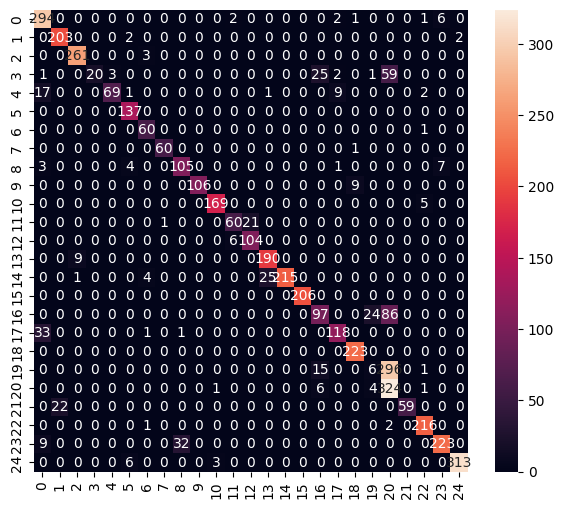

Classification Report
              precision    recall  f1-score   support

           0       0.82      0.96      0.89       306
           1       0.90      0.98      0.94       207
           2       0.96      0.99      0.98       264
           3       1.00      0.18      0.31       111
           4       0.96      0.70      0.81        99
           5       0.91      1.00      0.95       137
           6       0.87      0.98      0.92        61
           7       0.98      0.98      0.98        61
           8       0.76      0.88      0.81       120
           9       1.00      0.92      0.96       115
          10       0.98      0.97      0.97       174
          11       0.88      0.73      0.80        82
          12       0.83      0.95      0.89       110
          13       0.88      0.95      0.92       199
          14       1.00      0.88      0.93       245
          15       1.00      1.00      1.00       206
          16       0.68      0.47      0.55       207
     

In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

def print_confusion_matrix(y_true, y_pred, report=True):
    labels = sorted(list(set(y_true)))
    cmx_data = confusion_matrix(y_true, y_pred, labels=labels)
    
    df_cmx = pd.DataFrame(cmx_data, index=labels, columns=labels)
 
    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(df_cmx, annot=True, fmt='g' ,square=False)
    ax.set_ylim(len(set(y_true)), 0)
    plt.show()
    
    if report:
        print('Classification Report')
        print(classification_report(y_test, y_pred))

Y_pred = model.predict(X_test)
y_pred = np.argmax(Y_pred, axis=1)

print_confusion_matrix(y_test, y_pred)

# Convert to model for Tensorflow-Lite

In [16]:
# Save as a model dedicated to inference
model.save(model_save_path, include_optimizer=False)

c:\Users\markl\anaconda3\envs\opencv_env\lib\site-packages\keras\src\engine\training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [17]:
# Transform model (quantization)
tflite_save_path = 'model/keypoint_classifier/keypoint_classifier.tflite'

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_quantized_model = converter.convert()

open(tflite_save_path, 'wb').write(tflite_quantized_model)

INFO:tensorflow:Assets written to: C:\Users\markl\AppData\Local\Temp\tmplu9_gxjr\assets


INFO:tensorflow:Assets written to: C:\Users\markl\AppData\Local\Temp\tmplu9_gxjr\assets


7468

# Inference test

In [18]:
interpreter = tf.lite.Interpreter(model_path=tflite_save_path)
interpreter.allocate_tensors()

In [19]:
# Get I / O tensor
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

In [20]:
interpreter.set_tensor(input_details[0]['index'], np.array([X_test[0]]))

In [21]:
%%time
# Inference implementation
interpreter.invoke()
tflite_results = interpreter.get_tensor(output_details[0]['index'])

CPU times: total: 0 ns
Wall time: 2.42 ms


In [22]:
print(np.squeeze(tflite_results))
print(np.argmax(np.squeeze(tflite_results)))

[2.0882578e-03 1.3397849e-02 5.6427587e-05 2.6652295e-02 5.2409158e-03
 4.0859271e-05 3.7350426e-05 9.5781850e-08 5.0923578e-04 1.2127422e-05
 2.2429605e-03 1.8647957e-05 5.5688284e-05 2.1611656e-04 9.1752700e-06
 1.0162959e-05 1.0335836e-01 1.4145549e-03 1.4569287e-06 3.3784953e-01
 4.8329288e-01 1.9726230e-02 1.2877386e-03 2.1187839e-04 2.2693402e-03]
20
